# Analisis dan Klasterisasi Tingkat Konsumsi Energi Per Kapita di Indonesia (2021–2025) Menggunakan Algoritma K-Means

#Proyek Machine Learning ini bertujuan untuk mengelompokkan kabupaten/kota di Indonesia berdasarkan profil dan tren konsumsi energi per kapita dari tahun 2021 hingga 2025. Metode yang digunakan adalah **Unsupervised Learning** dengan algoritma **K-Means Clustering**.

#Alur Pengerjaan:
#1. Data Loading: Memuat dataset ke dalam Pandas DataFrame.
#2. Data Cleaning: Memeriksa dan menangani missing values serta duplikasi data.
#3. Data Preprocessing: Melakukan *pivoting* data dan standarisasi fitur (*scaling*).
#4. Exploratory Data Analysis (EDA): Menampilkan statistik deskriptif dan distribusi data.
#5. Modelling: Menerapkan K-Means Clustering untuk mengelompokkan wilayah ke dalam 3 kategori (Rendah, Sedang, Tinggi).

In [8]:
# 1. DATA LOADING
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Memuat dataset
df = pd.read_csv('Konsumsi_energi_perkapita.csv')
df.columns = df.columns.str.strip() # Menghapus spasi pada nama kolom

print("Ukuran dataset awal:", df.shape)
df.head()

Ukuran dataset awal: (2570, 6)


,No,Kode Wilayah,Kabupaten_Kota,Provinsi,Tahun,Konsumsi_Energi
0,1,1109,Kabupaten Simeulue,Aceh,2021,1876
1,2,1110,Kabupaten Aceh Singkil,Aceh,2021,2228
2,3,1101,Kabupaten Aceh Selatan,Aceh,2021,2232
3,4,1102,Kabupaten Aceh Tenggara,Aceh,2021,2154
4,5,1103,Kabupaten Aceh Timur,Aceh,2021,2115


# 2. Data Cleaning & Preprocessing

#Pada tahap ini, kita melakukan:
#- Pemeriksaan missing values dan data duplikat pada dataset awal.
#- Transformasi data (pivoting) agar setiap baris mewakili 1 wilayah unik dengan kolom fitur konsumsi energi per tahun (2021–2025).
#- Penanganan nilai kosong pada data hasil pivoting.
#- Standarisasi data menggunakan `StandardScaler`.

In [9]:
# 2. DATA CLEANING
print("--- Cek Missing Values Awal ---")
print(df.isnull().sum())

print("\n--- Cek Data Duplikat ---")
print("Jumlah duplikat:", df.duplicated().sum())

# Pivoting Data
pivot_df = df.pivot(index=['Kode Wilayah', 'Kabupaten_Kota', 'Provinsi'], 
                    columns='Tahun', 
                    values='Konsumsi_Energi').reset_index()

# Menghapus baris dengan missing value setelah pivot (misal wilayah pemekaran baru)
clean_data = pivot_df.dropna().copy()
print("\nUkuran data setelah dibersihkan:", clean_data.shape)

# 3. DATA PREPROCESSING
features = [2021, 2022, 2023, 2024, 2025]
X = clean_data[features]

# Standarisasi / Scaling Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

clean_data.head()


--- Cek Missing Values Awal ---
No                 0
Kode Wilayah       0
Kabupaten_Kota     0
Provinsi           0
Tahun              0
Konsumsi_Energi    0
dtype: int64

--- Cek Data Duplikat ---
Jumlah duplikat: 0

Ukuran data setelah dibersihkan: (487, 8)


Tahun,Kode Wilayah,Kabupaten_Kota,Provinsi,2021,2022,2023,2024,2025
0,1101,Kabupaten Aceh Selatan,Aceh,2232.0,2031.0,1983.0,2051.0,2228.0
1,1102,Kabupaten Aceh Tenggara,Aceh,2154.0,2057.0,2166.0,2065.0,2115.0
2,1103,Kabupaten Aceh Timur,Aceh,2115.0,2120.0,2000.0,1923.0,1921.0
3,1104,Kabupaten Aceh Tengah,Aceh,2349.0,2117.0,2063.0,2170.0,2206.0
4,1105,Kabupaten Aceh Barat,Aceh,2467.0,2215.0,2051.0,2079.0,1946.0


#3. Exploratory Data Analysis (EDA)
#Tahap ini dilakukan untuk memahami karakteristik dan distribusi data konsumsi energi per kapita antar wilayah.

--- Statistik Deskriptif (2021-2025) ---
Tahun         2021         2022         2023         2024         2025
count   487.000000   487.000000   487.000000   487.000000   487.000000
mean   2107.794661  2044.114990  2066.466119  2027.386037  2047.032854
std     172.487105   219.081244   203.123375   179.354750   175.725946
min    1645.000000   191.000000   231.000000  1451.000000  1477.000000
25%    1995.000000  1926.000000  1955.000000  1910.500000  1931.000000
50%    2112.000000  2043.000000  2062.000000  2020.000000  2048.000000
75%    2212.000000  2160.500000  2164.500000  2134.000000  2152.500000
max    2968.000000  2827.000000  3015.000000  2780.000000  2823.000000


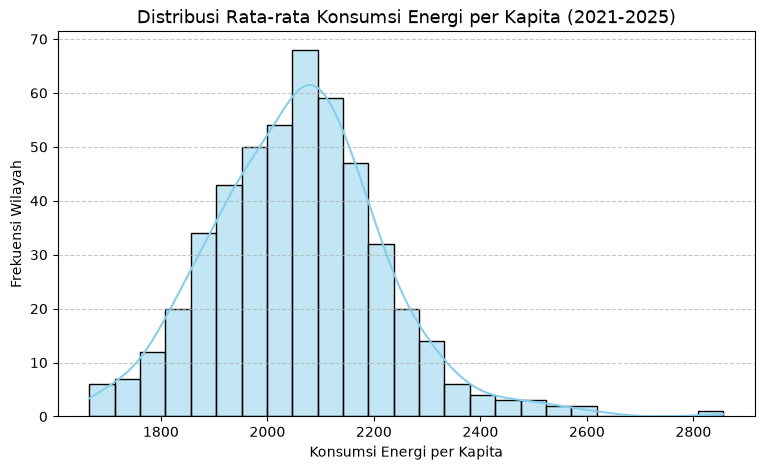

In [10]:
# 4. EDA & STATISTIK DESKRIPTIF
print("--- Statistik Deskriptif (2021-2025) ---")
print(clean_data[features].describe())

# Hitung Rata-rata Konsumsi per Wilayah
clean_data['Mean_Konsumsi'] = clean_data[features].mean(axis=1)

# Visualisasi Distribusi Rata-rata Konsumsi Energi
plt.figure(figsize=(9, 5))
sns.histplot(clean_data['Mean_Konsumsi'], kde=True, color='skyblue', bins=25)
plt.title('Distribusi Rata-rata Konsumsi Energi per Kapita (2021-2025)', fontsize=13)
plt.xlabel('Konsumsi Energi per Kapita')
plt.ylabel('Frekuensi Wilayah')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#4. Modelling (K-Means Clustering)

#Pada tahap ini, kita menerapkan algoritma K-Means dengan $K=3$ untuk mengelompokkan wilayah ke dalam 3 kategori:
#- Rendah: Wilayah dengan konsumsi energi relatif kecil.
#- Sedang: Wilayah dengan konsumsi energi rata-rata/menengah.
#- Tinggi: Wilayah dengan konsumsi energi sangat tinggi.

#>Catatan: Karena metode yang digunakan adalah Unsupervised Learning (Clustering), kita tidak memerlukan Data Splitting (train-test split).

In [11]:
# 5. MODELLING K-MEANS
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clean_data['Cluster'] = kmeans.fit_predict(X_scaled)

# Urutkan label klaster berdasarkan rata-rata konsumsi energi agar logis (Rendah, Sedang, Tinggi)
cluster_means = clean_data.groupby('Cluster')[features].mean().mean(axis=1).sort_values()
mapping = {
    cluster_means.index[0]: 'Rendah',
    cluster_means.index[1]: 'Sedang',
    cluster_means.index[2]: 'Tinggi'
}
clean_data['Label_Klaster'] = clean_data['Cluster'].map(mapping)

# Menampilkan Jumlah Anggota per Klaster
print("--- Jumlah Wilayah per Klaster ---")
print(clean_data['Label_Klaster'].value_counts())

# Menampilkan Sampel Hasil Klasterisasi
clean_data[['Kode Wilayah', 'Kabupaten_Kota', 'Provinsi', 'Label_Klaster'] + features].head(10)

--- Jumlah Wilayah per Klaster ---
Label_Klaster
Sedang    252
Rendah    172
Tinggi     63
Name: count, dtype: int64


Tahun,Kode Wilayah,Kabupaten_Kota,Provinsi,Label_Klaster,2021,2022,2023,2024,2025
0,1101,Kabupaten Aceh Selatan,Aceh,Sedang,2232.0,2031.0,1983.0,2051.0,2228.0
1,1102,Kabupaten Aceh Tenggara,Aceh,Sedang,2154.0,2057.0,2166.0,2065.0,2115.0
2,1103,Kabupaten Aceh Timur,Aceh,Sedang,2115.0,2120.0,2000.0,1923.0,1921.0
3,1104,Kabupaten Aceh Tengah,Aceh,Sedang,2349.0,2117.0,2063.0,2170.0,2206.0
4,1105,Kabupaten Aceh Barat,Aceh,Sedang,2467.0,2215.0,2051.0,2079.0,1946.0
5,1106,Kabupaten Aceh Besar,Aceh,Rendah,2044.0,1826.0,1892.0,1931.0,1937.0
6,1107,Kabupaten Pidie,Aceh,Sedang,2307.0,2210.0,2070.0,1940.0,2054.0
7,1108,Kabupaten Aceh Utara,Aceh,Rendah,1937.0,1935.0,1927.0,1722.0,2019.0
8,1109,Kabupaten Simeulue,Aceh,Rendah,1876.0,2132.0,2020.0,1829.0,1940.0
9,1110,Kabupaten Aceh Singkil,Aceh,Sedang,2228.0,2028.0,2188.0,2135.0,2016.0


In [12]:
import joblib

# Menyimpan model K-Means dan StandardScaler khusus energi ke file eksternal
joblib.dump(kmeans, 'kmeans_energy_model.joblib')
joblib.dump(scaler, 'energy_scaler.joblib')

print("Model K-Means dan Scaler berhasil disimpan untuk deployment!")

Model K-Means dan Scaler berhasil disimpan untuk deployment!
